# What adata contains what

The files are listed in the order of creation in "CustomBinning.ipynb".

In [1]:
import scanpy as sc
import os
import geopandas as gpd
import pandas as pd
from pathlib import Path

sample = Path("combined")
data_path = "data" / sample / "01_preprocessing/cell_seg_stardist/002um/custom_binning"

/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


**1.**  
**filtered_custom_bins.h5ad**  
We filter out any barcodes (bins), that are either in no nucleus or are in multiple nuclei at once (overlapping).
The resulting matrix contains all expressed genes per **bin**, not per nucleus.
- `.X`: rows (obs): Barcodes per one nucleus, Columns (var):	Genes from the 10x matrix, Values: Integer UMI counts
- `.obs`: 'in_tissue', 'array_row', 'array_col', 'pxl_row_in_fullres', 'pxl_col_in_fullres', index_x', 'index_y', 'id', 'is_within_polygon', 'is_not_in_an_polygon_overlap', 'Slide_ID'
- `.var`: 'gene_ids', 'feature_types', 'genome'

In [18]:
filtered_custom_bins = sc.read_h5ad(os.path.join(data_path, "filtered_custom_bins.h5ad"))
filtered_custom_bins

/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/anndata/_core/anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


AnnData object with n_obs × n_vars = 1721528 × 18085
    obs: 'in_tissue', 'array_row', 'array_col', 'pxl_row_in_fullres', 'pxl_col_in_fullres', 'index_x', 'index_y', 'id', 'is_within_polygon', 'is_not_in_an_polygon_overlap', 'Slide_ID'
    var: 'gene_ids', 'feature_types', 'genome'

In [19]:
filtered_custom_bins.obs

,in_tissue,array_row,array_col,pxl_row_in_fullres,pxl_col_in_fullres,index_x,index_y,id,is_within_polygon,is_not_in_an_polygon_overlap,Slide_ID
s_002um_02043_00141-1,1,2043,141,49055.614563,45360.824978,s_002um_02043_00141-1,s_002um_02043_00141-1,ID_1318569,True,True,CRC_P5
s_002um_03246_01880-1,1,3246,1880,40320.322188,58100.258125,s_002um_03246_01880-1,s_002um_03246_01880-1,ID_1056638,True,True,CRC_P5
s_002um_01050_01530-1,1,1050,1530,56350.990878,55477.439409,s_002um_01050_01530-1,s_002um_01050_01530-1,ID_1620019,True,True,CRC_P5
s_002um_01057_00712-1,1,1057,712,56275.268082,49502.109602,s_002um_01057_00712-1,s_002um_01057_00712-1,ID_1598983,True,True,CRC_P5
s_002um_00737_02449-1,1,737,2449,58665.104485,62181.512805,s_002um_00737_02449-1,s_002um_00737_02449-1,ID_1735286,True,True,CRC_P5
...,...,...,...,...,...,...,...,...,...,...,...
s_002um_01930_00297-1,1,1930,297,49885.719742,46496.957741,s_002um_01930_00297-1,s_002um_01930_00297-1,ID_1312732,True,True,CRC_P5
s_002um_00635_02644-1,1,635,2644,59416.094674,63602.988400,s_002um_00635_02644-1,s_002um_00635_02644-1,ID_1736877,True,True,CRC_P5
s_002um_00080_00956-1,1,80,956,63419.638408,51255.052050,s_002um_00080_00956-1,s_002um_00080_00956-1,ID_1755061,True,True,CRC_P5
s_002um_02017_00654-1,1,2017,654,49260.921104,49107.423831,s_002um_02017_00654-1,s_002um_02017_00654-1,ID_1321331,True,True,CRC_P5


  
**2.**  
**nuclei_grouped_UMI_count.h5ad**  
Structure: nucleus_IDs x embedding diension (i.e. length == no. of all possible expressed genes in nucleus)

- `.X`: unique nucleus IDs (row ID) x genes (**column**: gene ID, **cell**: summed expression of that gene over all bins in the nucleus)
- `obs`: nucleus ID, Slide_ID
- `.var`: gene ID, feature type, genome

In [5]:
nuclei_grouped_UMI_count = sc.read_h5ad(os.path.join(data_path, "nuclei_grouped_UMI_count.h5ad"))
nuclei_grouped_UMI_count.obs

/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/anndata/_core/anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


,id,Slide_ID
0,ID_9187,CRC_P2
1,ID_9205,CRC_P2
2,ID_9225,CRC_P2
3,ID_9268,CRC_P2
4,ID_9275,CRC_P2
...,...,...
305615,ID_838150,CRC_P2
305616,ID_838165,CRC_P2
305617,ID_838170,CRC_P2
305618,ID_838173,CRC_P2


**3.**  
**count_area_filtered_adata.h5ad**  
Builds on the previous anndata, but applies filters both to *nucleus area* and *gene expression*.  
We remove nuclei with an area larger than a threshold (i.e. 500), to avoid broken or merged nuclei.  
We also remove nuclei with a UMI count below a threshold. --> avoid empty or low-quality nuclei  
- `.X`: same as `nuclei_grouped_UMI_count`
- `.obs`: 'id', 'Slide_ID', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'clusters'
- `.var`: 'gene_ids', 'feature_types', 'genome', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
- `uns`: 'clusters', 'hvg', 'log1p', 'neighbors', 'pca'
- `obsm`: 'X_pca'
- `varm`: 'PCs'
- `obsp`: 'connectivities', 'distances'

In [4]:
count_area_filtered_adata = sc.read_h5ad(os.path.join(data_path, "count_area_filtered_adata.h5ad"))
count_area_filtered_adata.obsm["spatial"]

/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/anndata/_core/aligned_df.py:67: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


array([[14483.94729034, 14852.18330142],
       [14398.84626303, 14808.43803508],
       [14420.53323466, 14815.64692031],
       ...,
       [52011.77342141, 46081.97058063],
       [51697.22333779, 45714.80668372],
       [51902.31578278, 46217.22288367]])

In [ ]:
count_area_filtered_adata.var_names[count_area_filtered_adata.var_names.duplicated()]

Index(['TBCE', 'HSPA14', 'TMSB15B'], dtype='object')

In [ ]:
count_area_filtered_adata.var[count_area_filtered_adata.var_names == "TBCE"]

,gene_ids,feature_types,genome,n_cells_by_counts,mean_counts,log1p_mean_counts,pct_dropout_by_counts,total_counts,log1p_total_counts,highly_variable,means,dispersions,dispersions_norm
TBCE,ENSG00000285053,Gene Expression,GRCh38,237,0.004021,0.004013,99.599608,238.0,5.476464,False,0.003434,0.002397,-0.343069
TBCE,ENSG00000284770,Gene Expression,GRCh38,191,0.003244,0.003238,99.677321,192.0,5.262690,False,0.002547,-0.053013,-0.694714


**4.**  
**patch_assigned_count_area_filtered_adata.h5ad**  
Completely same structure as count_area_filtered_adata.h5ad. 
However, .obs now has a column that assigns it to a certain image patch from the original image.

- `.X`:
- `.obs`: 'id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'clusters', 'Slide_ID', 'Patch_ID'
- `.var`: 'gene_ids', 'feature_types', 'genome', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
- `.obsm`: 'X_pca'
- `.varm`: 'PCs'

In [ ]:
patch_assigned_count_area_filtered_adata = sc.read_h5ad(os.path.join(data_path2, "patch_assigned_count_area_filtered_adata.h5ad"))
patch_assigned_count_area_filtered_adata

**5.**  
**nuclei_geometry.parquet**
Contains nuclei geometry for each nucleus.

Structure columns: nucleus ID, geometry, Slide_ID


In [5]:
nuclei_geometry = gpd.read_parquet(os.path.join(data_path, "nuclei_geometry.parquet"))
nuclei_geometry

,id,geometry,Slide_ID,centroid,interior_centroid
0,ID_100013,"POLYGON ((16412.747 16770.000, 16411.831 16771...",CRC_P1,POINT (16402.898 16771.658),POINT (16402.688 16771.822)
1,ID_100015,"POLYGON ((15099.245 14928.000, 15101.909 14931...",CRC_P1,POINT (15087.663 14927.799),POINT (15087.165 14927.117)
2,ID_100016,"POLYGON ((15808.291 14890.000, 15808.276 14891...",CRC_P1,POINT (15801.839 14891.113),POINT (15801.950 14891.725)
3,ID_100017,"POLYGON ((16733.960 15898.000, 16733.509 15898...",CRC_P1,POINT (16724.426 15893.065),POINT (16724.564 15893.277)
4,ID_100032,"POLYGON ((16487.416 16810.000, 16487.168 16811...",CRC_P1,POINT (16479.073 16813.421),POINT (16478.406 16813.951)
...,...,...,...,...,...
456876,ID_666491,"POLYGON ((52314.505 45776.000, 52314.601 45776...",Normal_P5,POINT (52310.871 45774.543),POINT (52311.142 45774.228)
456877,ID_666492,"POLYGON ((51664.354 46284.000, 51664.362 46284...",Normal_P5,POINT (51656.120 46288.063),POINT (51655.758 46288.416)
456878,ID_666496,"POLYGON ((52024.459 46084.000, 52024.903 46084...",Normal_P5,POINT (52011.773 46081.971),POINT (52011.576 46081.873)
456879,ID_666497,"POLYGON ((51702.852 45716.000, 51702.877 45716...",Normal_P5,POINT (51697.223 45714.807),POINT (51697.149 45714.896)


# SpaGCN results

In [2]:
import pandas as pd
import scanpy as sc

spagcn = sc.read_h5ad("Baselines/SpaGCN/results/CRC_P2/results_cluster_7.h5ad")
spagcn

AnnData object with n_obs × n_vars = 144296 × 17807
    obs: 'x1', 'x_array', 'y_array', 'x_pixel', 'y_pixel', 'pred', 'refined_pred'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'genename'
    uns: 'clusters', 'hvg', 'log1p', 'neighbors', 'pca'
    obsm: 'X_pca'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

In [4]:
spagcn.obs["refined_pred"].unique()

[0, 5, 1, 4, 3, 6, 2]
Categories (7, int64): [0, 1, 2, 3, 4, 5, 6]

In [5]:
spagcn.obs

,x1,x_array,y_array,x_pixel,y_pixel,pred,refined_pred
id,,,,,,,
ID_9187,1,519,2532,44611.827182,3936.127186,0,0
ID_9205,1,508,2532,44535.136268,3940.559428,5,5
ID_9225,1,511,2530,44551.987946,3951.589978,5,5
ID_9268,1,523,2533,44638.653759,3934.697314,0,0
ID_9275,1,514,2532,44576.256291,3938.473171,5,5
...,...,...,...,...,...,...,...
ID_838110,1,3290,99,64614.458946,21967.865712,5,5
ID_838150,1,3270,115,64466.349010,21850.096671,1,1
ID_838165,1,3296,53,64654.301892,22301.626635,0,5


# Random tests


In [1]:
import scanpy as sc
adata = sc.read_h5ad("data/label_transfer_results/CRC_P2_with_annotation.h5ad")
adata

AnnData object with n_obs × n_vars = 8731400 × 18085
    obs: 'annotation', 'sample', 'disease_status'
    var: 'gene_ids', 'feature_types', 'genome'
    layers: None (.X)

In [6]:
import scanpy as sc
patches = sc.read_h5ad("data/CRC_P2/01_preprocessing/unimodel/metadata/WSI_patch_metadata.h5ad")
patches.obs

,Slide_ID,Patch_ID,X,Y,tissuetype,tissuetype_confidence,n_visium_bins
CRC_P2_patch_1.png,CRC_P2,patch_1.png,40580,0,NaN,NaN,0
CRC_P2_patch_10.png,CRC_P2,patch_10.png,40580,2016,NaN,NaN,0
CRC_P2_patch_100.png,CRC_P2,patch_100.png,40580,22176,Smooth Muscle,1.0,798
CRC_P2_patch_1000.png,CRC_P2,patch_1000.png,42596,20160,Smooth Muscle,1.0,925
CRC_P2_patch_10000.png,CRC_P2,patch_10000.png,62756,0,NaN,NaN,0
...,...,...,...,...,...,...,...
CRC_P2_patch_9995.png,CRC_P2,patch_9995.png,62532,21504,Neoplasm,1.0,936
CRC_P2_patch_9996.png,CRC_P2,patch_9996.png,62532,21728,Neoplasm,1.0,516
CRC_P2_patch_9997.png,CRC_P2,patch_9997.png,62532,21952,Neoplasm,1.0,434
CRC_P2_patch_9998.png,CRC_P2,patch_9998.png,62532,22176,Neoplasm,1.0,625


/tmp/ipykernel_141303/1272375572.py:9: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


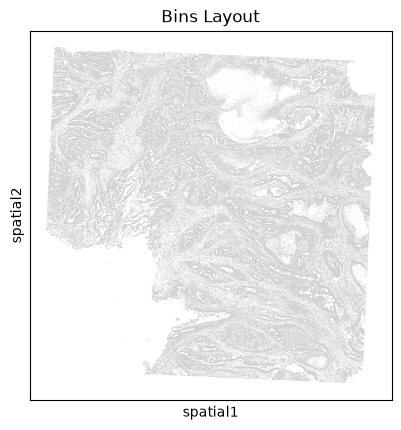

In [9]:
import scanpy as sc

# 1. Store coordinates
filtered_custom_bins.obsm["spatial"] = filtered_custom_bins.obs[
    ["pxl_col_in_fullres", "pxl_row_in_fullres"]
].values

# 2. Plot with img_key=None
sc.pl.spatial(
    filtered_custom_bins,
    color=None,
    spot_size=5,
    img_key=None,  # <--- Bypasses image lookup
    title="Bins Layout",
)

In [1]:
import pandas as pd
data = pd.read_parquet("data/CRC_P2/ground_truth/bin_patch_clusters.parquet")
data

,barcode,tissuetype,in_tissue,Patch_ID,leiden_0.2,leiden_0.5,leiden_1.0,leiden_2.0,intersection_area,cell_area,percent_covered
0,s_002um_02058_00301-1,Neoplasm,1,patch_1043.png,4,1,0,13,53.346963,53.346963,1.000000
5946252,s_002um_02422_00505-1,Neoplasm,1,patch_1739.png,5,3,3,37,53.346963,53.346963,1.000000
5946250,s_002um_00837_01462-1,Connective Tissue,1,patch_4922.png,1,6,21,24,53.346963,53.346963,1.000000
5946249,s_002um_00071_01530-1,Connective Tissue,1,patch_5048.png,1,6,25,21,53.346963,53.346963,1.000000
5946246,s_002um_02399_01615-1,Neoplasm,1,patch_5376.png,4,1,0,17,53.346963,53.346963,1.000000
...,...,...,...,...,...,...,...,...,...,...,...
8172626,s_002um_02754_01989-1,Neoplasm,1,patch_6577.png,4,1,0,17,13.883024,53.346963,0.260240
7069703,s_002um_02417_02024-1,Neoplasm,1,patch_6689.png,4,1,0,11,13.803251,53.346963,0.258745
3788075,s_002um_02433_03251-1,Neoplasm,1,patch_10829.png,4,1,0,17,13.751718,53.346963,0.257779
7223129,s_002um_00105_01164-1,Smooth Muscle,1,patch_3935.png,12,17,22,27,13.670340,53.346963,0.256253


In [7]:
import scanpy as sc
patches = sc.read_h5ad("data/CRC_P2/01_preprocessing/unimodel/metadata/WSI_patch_metadata.h5ad")
patches

AnnData object with n_obs × n_vars = 11110 × 1536
    obs: 'Slide_ID', 'Patch_ID', 'X', 'Y'
    obsm: 'spatial'
    layers: None (.X)

In [16]:
# ============================================================
# TRANSFER TISSUETYPE COMPOSITION + CONFIDENCE TO PATCH H5AD
# ============================================================
#
# Each patch receives a label containing ALL tissuetypes found
# among its Visium HD bins.
#
# Tissue types are ordered by number of bins:
#
#   largest tissue component -> smallest tissue component
#
# Example:
#
#   Neoplasm: 700 bins
#   Veins:    200 bins
#
# becomes:
#
#   tissuetype = "Neoplasm_Veins"
#   confidence = 0.778
#
# ============================================================

import os
import shutil
import numpy as np
import pandas as pd
from scipy.spatial import cKDTree
import scanpy as sc


PATCH_SIZE = 224


# ============================================================
# 1. FILE PATH
# ============================================================

PATCH_H5AD = (
    "data/CRC_P2/01_preprocessing/"
    "unimodel/metadata/"
    "WSI_patch_metadata.h5ad"
)

adata = sc.read_h5ad(
    PATCH_H5AD
)

print(adata)
print("\nPatch metadata:")
print(adata.obs.head())


# ============================================================
# 2. MAKE BACKUP BEFORE MODIFYING H5AD
# ============================================================

backup_path = PATCH_H5AD.replace(
    ".h5ad",
    "_before_tissuetype_transfer.h5ad"
)

if not os.path.exists(backup_path):

    print("Creating backup:")
    print(backup_path)

    shutil.copy2(
        PATCH_H5AD,
        backup_path
    )

else:

    print("Backup already exists:")
    print(backup_path)


# ============================================================
# 3. PREPARE VISIUM BIN DATA
# ============================================================

ANNOTATION_CSV = (
    "data/CRC_P2/ground_truth/"
    "bin_patch_clusters.parquet"
)

TISSUE_POSITIONS = (
    "data/CRC_P2/output/binned_outputs/"
    "square_002um/spatial/"
    "tissue_positions.parquet"
)

# Load annotation labels
annotations = pd.read_parquet(
    ANNOTATION_CSV
)

# Load Visium HD bin coordinates
positions = pd.read_parquet(
    TISSUE_POSITIONS
)

# Make barcode a column if necessary
if "barcode" not in positions.columns:
    positions = positions.reset_index()

# Rename full-resolution pixel coordinates
positions = positions.rename(
    columns={
        "pxl_col_in_fullres": "X_bin",
        "pxl_row_in_fullres": "Y_bin"
    }
)

# Keep only the columns needed for the transfer
positions_small = positions[
    [
        "barcode",
        "X_bin",
        "Y_bin"
    ]
].copy()

# Merge tissue labels with spatial coordinates
visium = annotations.merge(
    positions_small,
    on="barcode",
    how="left"
)

print(visium.columns.tolist())
print(visium.shape)


# ------------------------------------------------------------
# Numeric coordinates
# ------------------------------------------------------------

visium["X_bin"] = pd.to_numeric(
    visium["X_bin"],
    errors="coerce"
)

visium["Y_bin"] = pd.to_numeric(
    visium["Y_bin"],
    errors="coerce"
)


# ------------------------------------------------------------
# Valid coordinates
# ------------------------------------------------------------

valid_coords = (
    np.isfinite(visium["X_bin"]) &
    np.isfinite(visium["Y_bin"])
)


# ------------------------------------------------------------
# In-tissue mask
# ------------------------------------------------------------

in_tissue_values = (
    visium["in_tissue"]
    .astype(str)
    .str.lower()
    .str.strip()
)

in_tissue_mask = in_tissue_values.isin(
    ["1", "true", "yes"]
)


# ------------------------------------------------------------
# Valid tissue labels
# ------------------------------------------------------------

valid_tissue = (
    visium["tissuetype"].notna() &
    (
        visium["tissuetype"]
        .astype(str)
        .str.strip()
        != ""
    )
)


# ------------------------------------------------------------
# Keep usable bins
# ------------------------------------------------------------

visium = visium[
    valid_coords &
    in_tissue_mask &
    valid_tissue
].copy()


print("=" * 70)
print("VISIUM BINS USED FOR TRANSFER")
print("=" * 70)

print(
    f"\nValid in-tissue bins with tissuetype: "
    f"{len(visium):,}"
)


# ============================================================
# 4. BUILD SPATIAL KD-TREE
# ============================================================

bin_coordinates = visium[
    ["X_bin", "Y_bin"]
].to_numpy(dtype=float)

tree = cKDTree(
    bin_coordinates
)

print(
    "\nKD-tree created for "
    f"{len(bin_coordinates):,} Visium bins."
)


# ============================================================
# 5. PREPARE PATCHES
# ============================================================

patch_obs = adata.obs.copy()


patch_obs["X"] = pd.to_numeric(
    patch_obs["X"],
    errors="coerce"
)

patch_obs["Y"] = pd.to_numeric(
    patch_obs["Y"],
    errors="coerce"
)


# ============================================================
# 6. TRANSFER LABELS
# ============================================================

results = []

print("\n" + "=" * 70)
print("TRANSFERRING TISSUETYPE COMPOSITIONS")
print("=" * 70)


for counter, (patch_index, patch) in enumerate(
    patch_obs.iterrows()
):

    x0 = patch["X"]
    y0 = patch["Y"]


    # --------------------------------------------------------
    # Invalid patch coordinates
    # --------------------------------------------------------

    if (
        not np.isfinite(x0)
        or
        not np.isfinite(y0)
    ):

        results.append({
            "patch_index": patch_index,
            "tissuetype": np.nan,
            "tissuetype_confidence": np.nan,
            "n_visium_bins": 0
        })

        continue


    # --------------------------------------------------------
    # Patch boundaries
    # --------------------------------------------------------

    x1 = x0 + PATCH_SIZE
    y1 = y0 + PATCH_SIZE


    # --------------------------------------------------------
    # Patch center
    # --------------------------------------------------------

    cx = x0 + PATCH_SIZE / 2
    cy = y0 + PATCH_SIZE / 2


    # --------------------------------------------------------
    # Search radius
    #
    # Radius = distance from center to corner
    # --------------------------------------------------------

    radius = np.sqrt(
        (PATCH_SIZE / 2) ** 2 +
        (PATCH_SIZE / 2) ** 2
    )


    candidate_indices = tree.query_ball_point(
        [cx, cy],
        r=radius
    )


    # --------------------------------------------------------
    # No nearby bins
    # --------------------------------------------------------

    if len(candidate_indices) == 0:

        results.append({
            "patch_index": patch_index,
            "tissuetype": np.nan,
            "tissuetype_confidence": np.nan,
            "n_visium_bins": 0
        })

        continue


    # --------------------------------------------------------
    # Get candidate bins
    # --------------------------------------------------------

    candidates = visium.iloc[
        candidate_indices
    ]


    # --------------------------------------------------------
    # Keep only bins actually inside the patch
    # --------------------------------------------------------

    inside = (
        (candidates["X_bin"] >= x0) &
        (candidates["X_bin"] < x1) &
        (candidates["Y_bin"] >= y0) &
        (candidates["Y_bin"] < y1)
    )

    bins = candidates.loc[inside]


    # --------------------------------------------------------
    # No bins inside patch
    # --------------------------------------------------------

    if len(bins) == 0:

        results.append({
            "patch_index": patch_index,
            "tissuetype": np.nan,
            "tissuetype_confidence": np.nan,
            "n_visium_bins": 0
        })

        continue


    # ========================================================
    # COUNT ALL TISSUE TYPES
    # ========================================================

    counts = (
        bins["tissuetype"]
        .value_counts()
    )


    # --------------------------------------------------------
    # Sort largest -> smallest
    # --------------------------------------------------------

    counts = counts.sort_values(
        ascending=False
    )


    # ========================================================
    # CREATE COMBINED LABEL
    # ========================================================
    #
    # Example:
    #
    # Connective Tissue    500
    # Neoplasm             300
    # Veins                100
    #
    # becomes:
    #
    # Connective Tissue_Neoplasm_Veins
    #
    # --------------------------------------------------------

    tissue_components = [
        str(tissue)
        for tissue in counts.index
    ]


    combined_label = "_".join(
        tissue_components
    )


    # ========================================================
    # CONFIDENCE
    # ========================================================
    #
    # Confidence = fraction of bins belonging to the
    # dominant tissue type.
    #
    # Example:
    #
    # Neoplasm = 700
    # Veins    = 200
    #
    # confidence = 700 / 900 = 0.778
    #
    # --------------------------------------------------------

    dominant_count = counts.iloc[0]

    confidence = (
        dominant_count /
        len(bins)
    )


    # ========================================================
    # STORE RESULT
    # ========================================================

    results.append({

        "patch_index":
            patch_index,

        "tissuetype":
            combined_label,

        "tissuetype_confidence":
            confidence,

        "n_visium_bins":
            len(bins)
    })


    # --------------------------------------------------------
    # Progress
    # --------------------------------------------------------

    if (counter + 1) % 1000 == 0:

        print(
            f"Processed "
            f"{counter + 1:,} / "
            f"{len(patch_obs):,} patches"
        )


# ============================================================
# 7. CREATE TRANSFER TABLE
# ============================================================

transfer = pd.DataFrame(
    results
)

transfer = transfer.set_index(
    "patch_index"
)


# Make absolutely sure ordering matches AnnData
transfer = transfer.loc[
    adata.obs.index
]


# ============================================================
# 8. ADD LABELS TO H5AD
# ============================================================

adata.obs["tissuetype"] = (
    transfer["tissuetype"]
)

adata.obs["tissuetype_confidence"] = (
    transfer["tissuetype_confidence"]
)

adata.obs["n_visium_bins"] = (
    transfer["n_visium_bins"]
)


# ============================================================
# 9. SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("TRANSFER SUMMARY")
print("=" * 70)


n_total = len(
    adata.obs
)

n_labeled = (
    adata.obs["tissuetype"]
    .notna()
    .sum()
)

n_unlabeled = (
    adata.obs["tissuetype"]
    .isna()
    .sum()
)


print(
    f"\nTotal patches:         {n_total:,}"
)

print(
    f"Patches labeled:       {n_labeled:,}"
)

print(
    f"Patches without label: {n_unlabeled:,}"
)

print(
    f"\nPercentage labeled: "
    f"{100 * n_labeled / n_total:.2f}%"
)


# ============================================================
# 10. SHOW EXAMPLES
# ============================================================

print("\n" + "=" * 70)
print("EXAMPLE TRANSFERRED LABELS")
print("=" * 70)

print(
    adata.obs[
        [
            "X",
            "Y",
            "Patch_ID",
            "tissuetype",
            "tissuetype_confidence",
            "n_visium_bins"
        ]
    ].head(20).to_string()
)


# ============================================================
# 11. TISSUE COMBINATION DISTRIBUTION
# ============================================================

print("\n" + "=" * 70)
print("MOST COMMON TISSUE COMBINATIONS")
print("=" * 70)

print(
    adata.obs[
        "tissuetype"
    ]
    .value_counts(
        dropna=False
    )
    .head(30)
)


# ============================================================
# 12. CONFIDENCE DISTRIBUTION
# ============================================================

print("\n" + "=" * 70)
print("CONFIDENCE DISTRIBUTION")
print("=" * 70)

print(
    adata.obs[
        "tissuetype_confidence"
    ].describe(
        percentiles=[
            0.01,
            0.05,
            0.10,
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99
        ]
    )
)


# ============================================================
# 13. SAVE TRANSFER TABLE
# ============================================================

transfer_csv = PATCH_H5AD.replace(
    ".h5ad",
    "_tissuetype_transfer.csv"
)

transfer.to_csv(
    transfer_csv
)

print(
    "\nTransfer table saved to:"
)

print(
    os.path.abspath(
        transfer_csv
    )
)


# ============================================================
# 14. SAVE H5AD BACK TO ORIGINAL LOCATION
# ============================================================

adata.write_h5ad(
    PATCH_H5AD
)

print(
    "\nAnnotated H5AD saved to:"
)

print(
    os.path.abspath(
        PATCH_H5AD
    )
)


print(
    "\nBackup of original H5AD saved to:"
)

print(
    os.path.abspath(
        backup_path
    )
)

AnnData object with n_obs × n_vars = 11110 × 1536
    obs: 'Slide_ID', 'Patch_ID', 'X', 'Y', 'tissuetype', 'tissuetype_confidence', 'n_visium_bins'
    obsm: 'spatial'
    layers: None (.X)

Patch metadata:
                       Slide_ID         Patch_ID      X      Y     tissuetype  \
CRC_P2_patch_1.png       CRC_P2      patch_1.png  40580      0            NaN   
CRC_P2_patch_10.png      CRC_P2     patch_10.png  40580   2016            NaN   
CRC_P2_patch_100.png     CRC_P2    patch_100.png  40580  22176  Smooth Muscle   
CRC_P2_patch_1000.png    CRC_P2   patch_1000.png  42596  20160  Smooth Muscle   
CRC_P2_patch_10000.png   CRC_P2  patch_10000.png  62756      0            NaN   

                        tissuetype_confidence  n_visium_bins  
CRC_P2_patch_1.png                        NaN              0  
CRC_P2_patch_10.png                       NaN              0  
CRC_P2_patch_100.png                      1.0            798  
CRC_P2_patch_1000.png                     1.0         

Tissue types found:
  - Connective Tissue
  - Connective Tissue_Neoplasm
  - Connective Tissue_Neoplasm_Non-neoplastic Epithelium
  - Connective Tissue_Non-neoplastic Epithelium
  - Connective Tissue_Non-neoplastic Epithelium_Neoplasm
  - Connective Tissue_Non-neoplastic Epithelium_Smooth Muscle
  - Connective Tissue_Smooth Muscle
  - Connective Tissue_Smooth Muscle_Non-neoplastic Epithelium
  - Connective Tissue_Smooth Muscle_Veins
  - Connective Tissue_Veins
  - Connective Tissue_Veins_Smooth Muscle
  - Connective Tissue_Veins_Vessel
  - Connective Tissue_Vessel
  - Neoplasm
  - Neoplasm_Connective Tissue
  - Neoplasm_Connective Tissue_Non-neoplastic Epithelium
  - Neoplasm_Non-neoplastic Epithelium
  - Neoplasm_Non-neoplastic Epithelium_Connective Tissue
  - Non-neoplastic Epithelium
  - Non-neoplastic Epithelium_Connective Tissue
  - Non-neoplastic Epithelium_Connective Tissue_Neoplasm
  - Non-neoplastic Epithelium_Connective Tissue_Smooth Muscle
  - Non-neoplastic Epithelium_Neopl

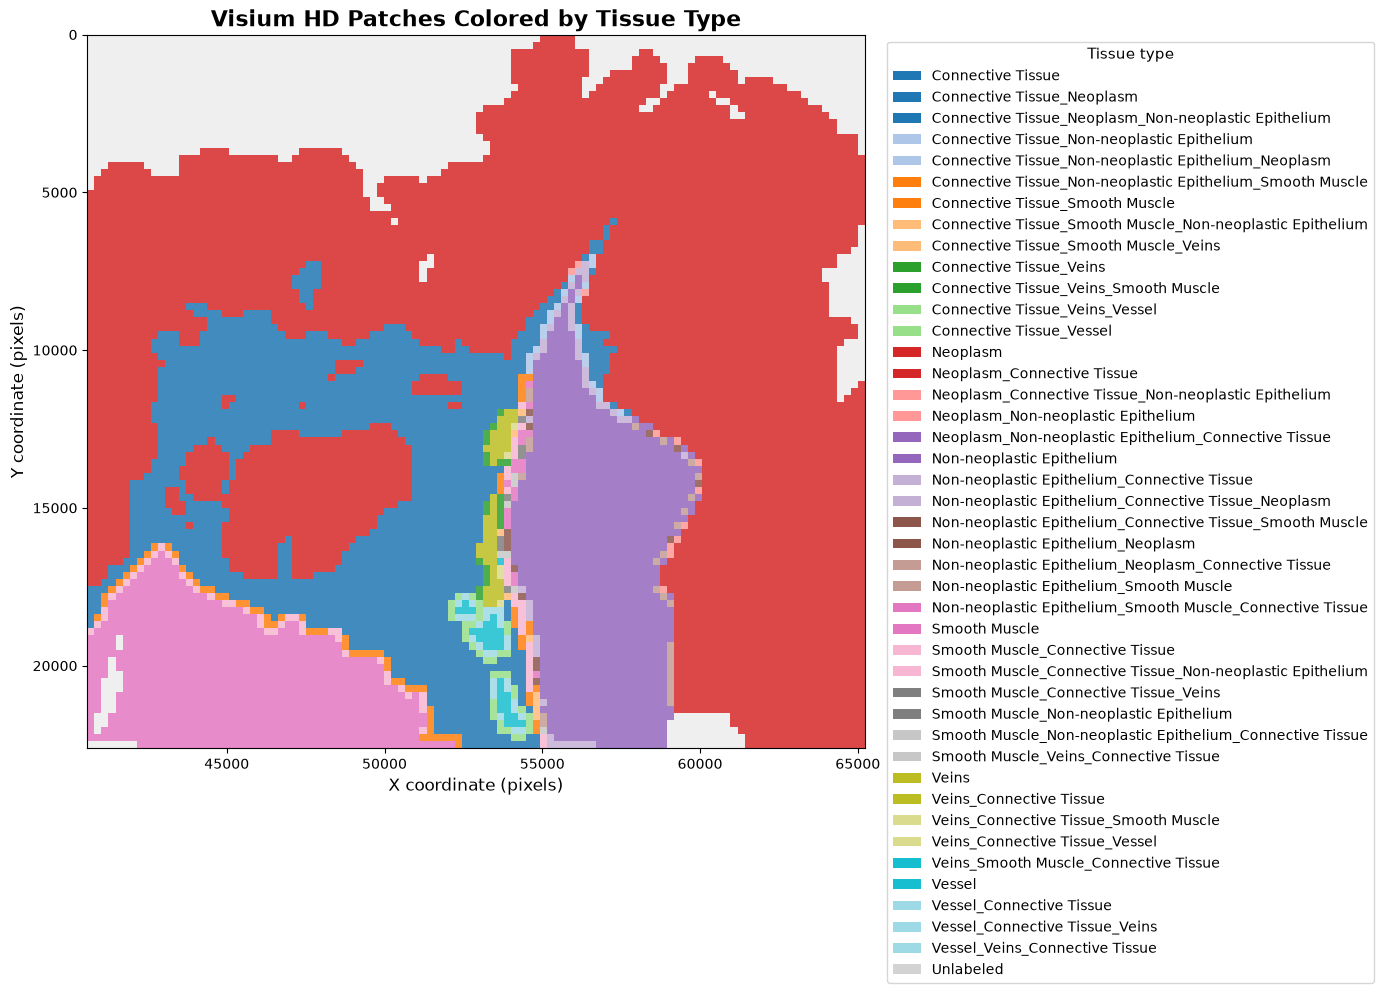


Saved:
   /home/charlottewolf/Documents/Arbeit/UKA_Arbeit/Projects/Genomosaic/patches_tissuetype_spatial_map.png
   /home/charlottewolf/Documents/Arbeit/UKA_Arbeit/Projects/Genomosaic/patches_tissuetype_spatial_map.pdf


In [17]:
# ============================================================
# PLOT PATCHES COLORED BY TISSUETYPE
# ============================================================

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.colors import ListedColormap
import numpy as np
import pandas as pd
import os


PATCH_SIZE = 224

# ------------------------------------------------------------
# 1. GET PATCH INFORMATION
# ------------------------------------------------------------

plot_df = adata.obs[
    [
        "X",
        "Y",
        "tissuetype",
        "tissuetype_confidence"
    ]
].copy()

plot_df["X"] = pd.to_numeric(
    plot_df["X"],
    errors="coerce"
)

plot_df["Y"] = pd.to_numeric(
    plot_df["Y"],
    errors="coerce"
)

plot_df = plot_df.dropna(
    subset=["X", "Y"]
).copy()


# ------------------------------------------------------------
# 2. GET TISSUE TYPES
# ------------------------------------------------------------

tissue_types = sorted(
    plot_df["tissuetype"]
    .dropna()
    .unique()
)

print("Tissue types found:")
for tissue in tissue_types:
    print("  -", tissue)

print(
    f"\nNumber of tissue types: "
    f"{len(tissue_types)}"
)


# ------------------------------------------------------------
# 3. CREATE COLORS
# ------------------------------------------------------------

# A color palette that works well for categorical tissue types
palette = [
    "#E41A1C",  # red
    "#377EB8",  # blue
    "#4DAF4A",  # green
    "#984EA3",  # purple
    "#FF7F00",  # orange
    "#A65628",  # brown
    "#F781BF",  # pink
    "#17BECF",  # cyan
    "#BCBD22",  # olive
    "#7F7F7F",  # gray
    "#FFD92F",  # yellow
    "#66C2A5",  # teal
    "#FC8D62",  # salmon
    "#8DA0CB",  # lavender-blue
    "#E78AC3",  # pink-purple
]

# If more tissue types than colors, use tab20
if len(tissue_types) > len(palette):

    cmap = plt.get_cmap(
        "tab20",
        len(tissue_types)
    )

    colors = [
        cmap(i)
        for i in range(len(tissue_types))
    ]

else:

    colors = palette[:len(tissue_types)]


color_map = dict(
    zip(
        tissue_types,
        colors
    )
)


# ------------------------------------------------------------
# 4. CREATE FIGURE
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(14, 14)
)


# ------------------------------------------------------------
# 5. DRAW EACH PATCH
# ------------------------------------------------------------

for _, row in plot_df.iterrows():

    x = row["X"]
    y = row["Y"]

    tissue = row["tissuetype"]

    # Unlabeled patches = light gray
    if pd.isna(tissue):

        facecolor = "#D3D3D3"
        alpha = 0.35

    else:

        facecolor = color_map[tissue]
        alpha = 0.85

    rect = Rectangle(
        (x, y),
        PATCH_SIZE,
        PATCH_SIZE,
        facecolor=facecolor,
        edgecolor="none",
        alpha=alpha
    )

    ax.add_patch(rect)


# ------------------------------------------------------------
# 6. AXIS LIMITS
# ------------------------------------------------------------

xmin = plot_df["X"].min()
xmax = plot_df["X"].max() + PATCH_SIZE

ymin = plot_df["Y"].min()
ymax = plot_df["Y"].max() + PATCH_SIZE

ax.set_xlim(
    xmin,
    xmax
)

ax.set_ylim(
    ymax,
    ymin
)


# ------------------------------------------------------------
# 7. LABELS
# ------------------------------------------------------------

ax.set_xlabel(
    "X coordinate (pixels)",
    fontsize=12
)

ax.set_ylabel(
    "Y coordinate (pixels)",
    fontsize=12
)

ax.set_title(
    "Visium HD Patches Colored by Tissue Type",
    fontsize=16,
    fontweight="bold"
)

ax.set_aspect(
    "equal"
)


# ------------------------------------------------------------
# 8. LEGEND
# ------------------------------------------------------------

legend_handles = []

for tissue in tissue_types:

    patch = Rectangle(
        (0, 0),
        1,
        1,
        facecolor=color_map[tissue],
        edgecolor="none"
    )

    legend_handles.append(
        patch
    )


# Add unlabeled
if plot_df["tissuetype"].isna().any():

    legend_handles.append(
        Rectangle(
            (0, 0),
            1,
            1,
            facecolor="#D3D3D3",
            edgecolor="none"
        )
    )

    legend_labels = (
        tissue_types +
        ["Unlabeled"]
    )

else:

    legend_labels = tissue_types


ax.legend(
    legend_handles,
    legend_labels,
    title="Tissue type",
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    frameon=True,
    fontsize=10,
    title_fontsize=11
)


# ------------------------------------------------------------
# 9. CLEAN UP
# ------------------------------------------------------------

ax.grid(
    False
)

plt.tight_layout()


# ------------------------------------------------------------
# 10. SAVE
# ------------------------------------------------------------

output_png = "patches_tissuetype_spatial_map.png"
output_pdf = "patches_tissuetype_spatial_map.pdf"

plt.savefig(
    output_png,
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    output_pdf,
    bbox_inches="tight"
)

plt.show()


print("\nSaved:")
print("  ", os.path.abspath(output_png))
print("  ", os.path.abspath(output_pdf))

LOADED DATA

Annotation file:
(8650159, 11)
['barcode', 'tissuetype', 'in_tissue', 'Patch_ID', 'leiden_0.2', 'leiden_0.5', 'leiden_1.0', 'leiden_2.0', 'intersection_area', 'cell_area', 'percent_covered']

Tissue positions:
(11222500, 6)
['barcode', 'in_tissue', 'array_row', 'array_col', 'pxl_row_in_fullres', 'pxl_col_in_fullres']

MERGING ANNOTATIONS WITH BIN COORDINATES

Annotated bins: 8,650,159
Bins after coordinate merge: 8,650,159
Bins with valid coordinates: 8,650,159

Bins plotted: 8,650,159
Bins excluded due to invalid coordinates: 0
Bins excluded due to missing tissuetype: 0

Tissue types:
  Connective Tissue: 1,756,535 bins
  Neoplasm: 4,937,259 bins
  Non-neoplastic Epithelium: 1,034,234 bins
  Smooth Muscle: 809,459 bins
  Veins: 52,774 bins
  Vessel: 59,898 bins

Estimated bin size:
  width  ≈ 0.00 pixels
  height ≈ 0.00 pixels


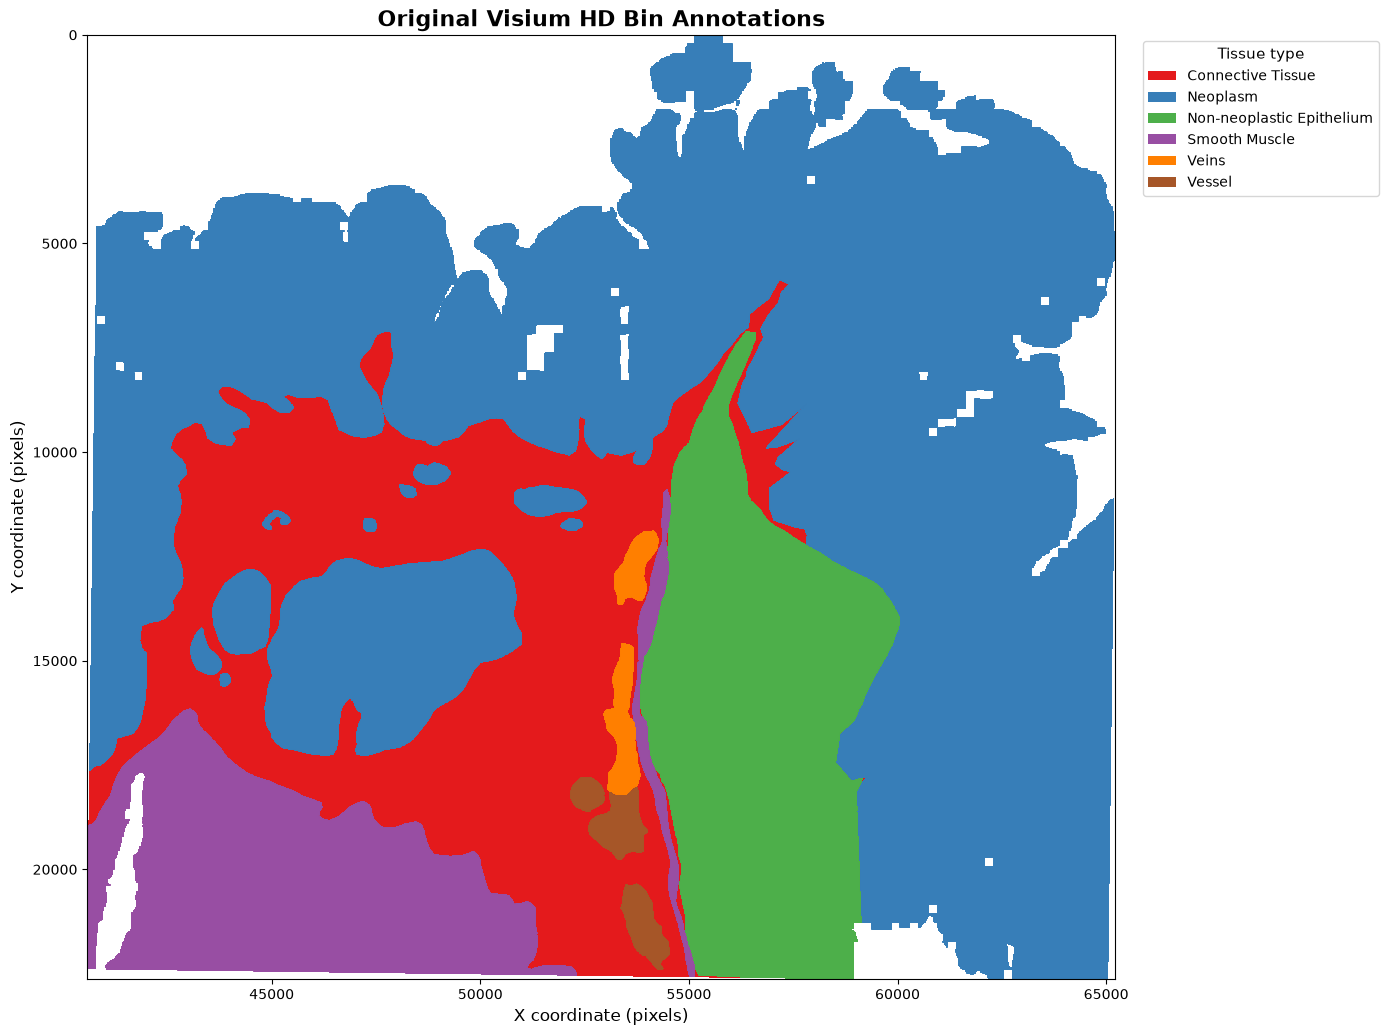


SAVED

PNG:
/home/charlottewolf/Documents/Arbeit/UKA_Arbeit/Projects/Genomosaic/original_visium_HD_tissuetype_map.png

PDF:
/home/charlottewolf/Documents/Arbeit/UKA_Arbeit/Projects/Genomosaic/original_visium_HD_tissuetype_map.pdf


In [15]:
# ============================================================
# ORIGINAL VISIUM HD BIN ANNOTATION MAP
# ============================================================
#
# Each Visium HD bin is plotted as a small square and colored
# according to its annotated tissuetype.
#
# Coordinates come from:
#   tissue_positions.parquet
#
# Labels come from:
#   bin_patch_clusters.parquet
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch


# ------------------------------------------------------------
# FILES
# ------------------------------------------------------------

ANNOTATION_CSV = (
    "data/CRC_P2/ground_truth/"
    "bin_patch_clusters.parquet"
)

TISSUE_POSITIONS = (
    "data/CRC_P2/output/binned_outputs/"
    "square_002um/spatial/"
    "tissue_positions.parquet"
)

PATCH_H5AD = (
    "data/CRC_P2/01_preprocessing/"
    "unimodel/metadata/"
    "WSI_patch_metadata.h5ad"
)

PATCH_SIZE = 224


# ------------------------------------------------------------
# 1. LOAD DATA
# ------------------------------------------------------------

annotations = pd.read_parquet(
    ANNOTATION_CSV
)

positions = pd.read_parquet(
    TISSUE_POSITIONS
)

print("=" * 70)
print("LOADED DATA")
print("=" * 70)

print("\nAnnotation file:")
print(
    annotations.shape
)

print(
    annotations.columns.tolist()
)

print("\nTissue positions:")
print(
    positions.shape
)

print(
    positions.columns.tolist()
)


# ------------------------------------------------------------
# 2. PREPARE TISSUE POSITIONS
# ------------------------------------------------------------

# Make barcode an ordinary column if it is currently the index
if "barcode" not in positions.columns:

    positions = positions.reset_index()

    # The index may have another name
    if "barcode" not in positions.columns:

        positions = positions.rename(
            columns={
                positions.columns[0]: "barcode"
            }
        )


# ------------------------------------------------------------
# Rename coordinate columns
# ------------------------------------------------------------

positions = positions.rename(
    columns={
        "pxl_col_in_fullres": "X_bin",
        "pxl_row_in_fullres": "Y_bin"
    }
)


# ------------------------------------------------------------
# 3. MERGE ANNOTATIONS WITH COORDINATES
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("MERGING ANNOTATIONS WITH BIN COORDINATES")
print("=" * 70)

# Only bring in the columns we actually need
position_columns = [
    "barcode",
    "in_tissue",
    "X_bin",
    "Y_bin"
]

position_columns = [
    c for c in position_columns
    if c in positions.columns
]

pos_small = positions[
    position_columns
].copy()


# Avoid duplicate in_tissue column if annotation already has it
if "in_tissue" in annotations.columns:
    pos_small = pos_small.drop(
        columns=["in_tissue"],
        errors="ignore"
    )


bins = annotations.merge(
    pos_small,
    on="barcode",
    how="left"
)


print(
    f"\nAnnotated bins: "
    f"{len(annotations):,}"
)

print(
    f"Bins after coordinate merge: "
    f"{len(bins):,}"
)

print(
    f"Bins with valid coordinates: "
    f"{bins[['X_bin', 'Y_bin']].notna().all(axis=1).sum():,}"
)


# ------------------------------------------------------------
# 4. KEEP ONLY BINS WE CAN PLOT
# ------------------------------------------------------------

bins["X_bin"] = pd.to_numeric(
    bins["X_bin"],
    errors="coerce"
)

bins["Y_bin"] = pd.to_numeric(
    bins["Y_bin"],
    errors="coerce"
)

valid_coords = (
    np.isfinite(bins["X_bin"]) &
    np.isfinite(bins["Y_bin"])
)

valid_tissue = (
    bins["tissuetype"].notna() &
    (
        bins["tissuetype"]
        .astype(str)
        .str.strip()
        != ""
    )
)

plot_bins = bins[
    valid_coords &
    valid_tissue
].copy()


print(
    f"\nBins plotted: "
    f"{len(plot_bins):,}"
)

print(
    f"Bins excluded due to invalid coordinates: "
    f"{(~valid_coords).sum():,}"
)

print(
    f"Bins excluded due to missing tissuetype: "
    f"{(
        valid_coords & ~valid_tissue
    ).sum():,}"
)


# ------------------------------------------------------------
# 5. TISSUE TYPES
# ------------------------------------------------------------

tissue_types = sorted(
    plot_bins["tissuetype"]
    .unique()
)

print("\nTissue types:")

for tissue in tissue_types:
    print(
        f"  {tissue}: "
        f"{(
            plot_bins['tissuetype'] == tissue
        ).sum():,} bins"
    )


# ------------------------------------------------------------
# 6. CREATE COLOR MAP
# ------------------------------------------------------------

palette = [
    "#E41A1C",  # red
    "#377EB8",  # blue
    "#4DAF4A",  # green
    "#984EA3",  # purple
    "#FF7F00",  # orange
    "#A65628",  # brown
    "#F781BF",  # pink
    "#17BECF",  # cyan
    "#BCBD22",  # olive
    "#FFD92F",  # yellow
    "#66C2A5",  # teal
    "#FC8D62",  # salmon
    "#8DA0CB",  # lavender
    "#E78AC3",  # pink-purple
    "#A6D854",  # lime
    "#FFD92F"
]

if len(tissue_types) > len(palette):

    cmap = plt.get_cmap(
        "tab20",
        len(tissue_types)
    )

    colors = [
        cmap(i)
        for i in range(len(tissue_types))
    ]

else:

    colors = palette[:len(tissue_types)]


color_map = dict(
    zip(
        tissue_types,
        colors
    )
)


# ------------------------------------------------------------
# 7. ESTIMATE BIN SIZE
# ------------------------------------------------------------
#
# Visium HD 2 µm bins should be much smaller than the 224 px
# patches. We estimate their apparent pixel size from the
# coordinate spacing.
#
# ------------------------------------------------------------

x_values = np.sort(
    plot_bins["X_bin"]
    .unique()
)

y_values = np.sort(
    plot_bins["Y_bin"]
    .unique()
)


def estimate_spacing(values):

    differences = np.diff(values)

    differences = differences[
        differences > 0
    ]

    if len(differences) == 0:
        return 2.0

    return np.median(
        differences
    )


bin_width = estimate_spacing(
    x_values
)

bin_height = estimate_spacing(
    y_values
)

print("\nEstimated bin size:")
print(
    f"  width  ≈ {bin_width:.2f} pixels"
)

print(
    f"  height ≈ {bin_height:.2f} pixels"
)


# ------------------------------------------------------------
# 8. PLOT
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(14, 14)
)


# ------------------------------------------------------------
# Plot each tissue type as a collection of small squares
# ------------------------------------------------------------

for tissue in tissue_types:

    subset = plot_bins[
        plot_bins["tissuetype"] == tissue
    ]

    ax.scatter(
        subset["X_bin"],
        subset["Y_bin"],
        s=max(
            bin_width * bin_height * 0.8,
            1
        ),
        marker="s",
        color=color_map[tissue],
        edgecolors="none",
        alpha=0.85,
        rasterized=True,
        label=tissue
    )


# ------------------------------------------------------------
# 9. COORDINATE LIMITS
# ------------------------------------------------------------

ax.set_xlim(
    plot_bins["X_bin"].min() - bin_width,
    plot_bins["X_bin"].max() + bin_width
)

ax.set_ylim(
    plot_bins["Y_bin"].max() + bin_height,
    plot_bins["Y_bin"].min() - bin_height
)


# ------------------------------------------------------------
# 10. LABELS
# ------------------------------------------------------------

ax.set_xlabel(
    "X coordinate (pixels)",
    fontsize=12
)

ax.set_ylabel(
    "Y coordinate (pixels)",
    fontsize=12
)

ax.set_title(
    "Original Visium HD Bin Annotations",
    fontsize=16,
    fontweight="bold"
)

ax.set_aspect(
    "equal"
)

ax.grid(
    False
)


# ------------------------------------------------------------
# 11. LEGEND
# ------------------------------------------------------------

legend_handles = [
    Patch(
        facecolor=color_map[tissue],
        edgecolor="none",
        label=tissue
    )
    for tissue in tissue_types
]

ax.legend(
    handles=legend_handles,
    title="Tissue type",
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    frameon=True,
    fontsize=10,
    title_fontsize=11
)


# ------------------------------------------------------------
# 12. SAVE
# ------------------------------------------------------------

output_png = (
    "original_visium_HD_tissuetype_map.png"
)

output_pdf = (
    "original_visium_HD_tissuetype_map.pdf"
)

plt.tight_layout()

plt.savefig(
    output_png,
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    output_pdf,
    bbox_inches="tight"
)

plt.show()


print("\n" + "=" * 70)
print("SAVED")
print("=" * 70)

print(
    "\nPNG:"
)

print(
    os.path.abspath(
        output_png
    )
)

print(
    "\nPDF:"
)

print(
    os.path.abspath(
        output_pdf
    )
)

In [8]:
test = sc.read_h5ad("data/CRC_P2/01_preprocessing/unimodel/metadata/WSI_patch_metadata.h5ad")
test

AnnData object with n_obs × n_vars = 11110 × 1536
    obs: 'Slide_ID', 'Patch_ID', 'X', 'Y', 'tissuetype', 'tissuetype_confidence', 'n_visium_bins'
    obsm: 'spatial'
    layers: None (.X)

In [4]:
PATCH_H5AD = (
    "data/CRC_P2/01_preprocessing/"
    "unimodel/metadata/"
    "filtered_WSI_patch_embeddings.h5ad"
)

import scanpy as sc
data = sc.read_h5ad(PATCH_H5AD)
data.obs

,Slide_ID,Patch_ID,X,Y,tissuetype,tissuetype_confidence,n_visium_bins,leiden_0.2,leiden_0.5,leiden_1.0,leiden_2.0
CRC_P2_patch_100.png,CRC_P2,patch_100.png,40580,22176,Smooth Muscle,1.0,798,3,7,11,24
CRC_P2_patch_1000.png,CRC_P2,patch_1000.png,42596,20160,Smooth Muscle,1.0,925,4,6,7,6
CRC_P2_patch_10008.png,CRC_P2,patch_10008.png,62756,1792,Neoplasm,1.0,413,3,7,15,28
CRC_P2_patch_10009.png,CRC_P2,patch_10009.png,62756,2016,Neoplasm,1.0,936,3,9,6,26
CRC_P2_patch_1001.png,CRC_P2,patch_1001.png,42596,20384,Smooth Muscle,1.0,947,4,6,7,6
...,...,...,...,...,...,...,...,...,...,...,...
CRC_P2_patch_9994.png,CRC_P2,patch_9994.png,62532,21280,Neoplasm,1.0,945,0,1,2,17
CRC_P2_patch_9995.png,CRC_P2,patch_9995.png,62532,21504,Neoplasm,1.0,936,3,7,11,15
CRC_P2_patch_9996.png,CRC_P2,patch_9996.png,62532,21728,Neoplasm,1.0,516,3,7,15,28
CRC_P2_patch_9997.png,CRC_P2,patch_9997.png,62532,21952,Neoplasm,1.0,434,3,7,15,28


In [6]:
data.obs["tissuetype"].value_counts()

tissuetype
Neoplasm                                                     5165
Connective Tissue                                            1463
Non-neoplastic Epithelium                                    1007
Smooth Muscle                                                 815
Neoplasm_Connective Tissue                                    238
Connective Tissue_Neoplasm                                    233
Connective Tissue_Smooth Muscle                                72
Smooth Muscle_Connective Tissue                                68
Non-neoplastic Epithelium_Connective Tissue                    42
Connective Tissue_Vessel                                       36
Vessel                                                         32
Vessel_Connective Tissue                                       27
Veins_Connective Tissue                                        26
Veins                                                          25
Neoplasm_Non-neoplastic Epithelium_Connective Tissue           22

In [5]:
import scanpy as sc
f_trans_adata = sc.read_h5ad("data/combined/01_preprocessing/cell_seg_stardist/002um/custom_binning/count_area_filtered_adata.h5ad")
f_trans_adata.obs["Slide_ID"].unique()

/home/charlottewolf/miniconda3/envs/autoencoder/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


['CRC_P1', 'CRC_P2', 'CRC_P5', 'Normal_P3', 'Normal_P5']
Categories (5, object): ['CRC_P1', 'CRC_P2', 'CRC_P5', 'Normal_P3', 'Normal_P5']